# Pipeline de inferencia end-to-end: del papel a LeNet

**Autor:** John Fredy Montenegro — Estudiante MIAA Icesi

Este notebook conecta las técnicas clásicas de procesamiento digital de imágenes con
una arquitectura fundacional de aprendizaje profundo (LeNet-5). El objetivo es tomar
una fotografía de dígitos escritos a mano, aislar cada número, estandarizarlo al
dominio del dataset MNIST y clasificarlo con un modelo pre-entrenado.

**Flujo general del pipeline**

1. **Captura de datos crudos:** foto tomada con la cámara o seleccionada desde el computador.
2. **Procesamiento y segmentación (OpenCV):** umbralización adaptativa, morfología,
   contornos y filtrado de ruido.
3. **Estandarización al dominio MNIST:** trazo blanco sobre fondo negro, grosor
   normalizado, relación de aspecto conservada, centrado por centro de masa y 28x28.
4. **Inferencia (forward pass):** clasificación con LeNet-5 y reconstrucción del número.

Cada etapa se documenta visualmente con imágenes intermedias y cierra con una
conclusión técnica que justifica los parámetros elegidos.

## Entorno recomendado

El notebook está pensado para ejecutarse en Google Colab. Se recomienda activar la GPU
en `Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU` para acelerar el
entrenamiento de LeNet. También funciona en un entorno local con Python 3 y las
dependencias de la celda siguiente.

Las celdas deben ejecutarse en orden, de arriba hacia abajo, porque cada etapa usa las
variables que produce la anterior.

In [1]:
# Dependencias. En Colab, OpenCV, TensorFlow, NumPy y Matplotlib ya estan instalados.
# Esta celda sirve de respaldo si se ejecuta en un entorno local.
import sys

try:
    import cv2
    import tensorflow as tf
    import numpy as np
    import matplotlib
    print("Dependencias disponibles:")
    print("  OpenCV      :", cv2.__version__)
    print("  TensorFlow  :", tf.__version__)
    print("  NumPy       :", np.__version__)
    print("  Matplotlib  :", matplotlib.__version__)
except ImportError:
    print("Instalando dependencias faltantes...")
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install",
                    "opencv-python-headless", "tensorflow", "numpy", "matplotlib"])

Dependencias disponibles:
  OpenCV      : 5.0.0
  TensorFlow  : 2.21.0
  NumPy       : 2.1.3
  Matplotlib  : 3.10.0


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Detecta si estamos en Colab para habilitar la captura por camara.
try:
    from google.colab.patches import cv2_imshow  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False


def mostrar(imagen, titulo="", cmap=None):
    """Muestra una imagen con Matplotlib (funciona en Colab y en local).

    OpenCV trabaja en formato BGR; para visualizar en color se convierte a RGB.
    """
    plt.figure(figsize=(6, 6))
    if imagen.ndim == 2:
        plt.imshow(imagen, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis("off")
    plt.show()


print("Entorno Colab:", EN_COLAB)

Entorno Colab: True


## Etapa 0 - Modelo LeNet-5 pre-entrenado sobre MNIST

Antes de procesar la foto se necesita un clasificador. LeNet-5 se entrena sobre MNIST
una sola vez y el modelo se guarda en disco (`lenet_mnist_aug.keras`); en ejecuciones
posteriores se carga directamente, sin repetir el entrenamiento.

**Arquitectura LeNet-5.** Tres capas convolucionales (6, 16 y 120 filtros, kernels de
5x5) intercaladas con submuestreo promedio, seguidas de dos capas densas (84 y 10
neuronas). La entrada es de 32x32 porque la versión original de LeCun agrega un borde
de 2 píxeles alrededor de los 28x28 de MNIST.

**Aumentación de datos.** Los dígitos de MNIST están centrados, rectos y tienen un
grosor muy uniforme; los de una foto real no. Durante el entrenamiento se aplican al
azar rotaciones (±15°), traslaciones (±10 %), zoom (±15 %) y engrosamiento del trazo.
La arquitectura no cambia: solo se enriquece la distribución de entrenamiento para que
el modelo tolere las variaciones de la escritura real.

In [3]:
import os
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, losses

# Nombre nuevo: asi no se reutiliza el modelo anterior entrenado sin aumentacion.
RUTA_MODELO = "lenet_mnist_aug.keras"


def construir_lenet(num_clases=10):
    """Define LeNet-5 para entradas de 32x32x1 y `num_clases` salidas (10 para MNIST)."""
    modelo = models.Sequential([
        layers.Input(shape=(32, 32, 1)),
        layers.Conv2D(6, kernel_size=(5, 5), activation="relu"),
        layers.AveragePooling2D(pool_size=(2, 2)),
        layers.Conv2D(16, kernel_size=(5, 5), activation="relu"),
        layers.AveragePooling2D(pool_size=(2, 2)),
        layers.Conv2D(120, kernel_size=(5, 5), activation="relu"),
        layers.Flatten(),
        layers.Dense(84, activation="relu"),
        layers.Dense(num_clases, activation="softmax"),
    ])
    modelo.compile(
        optimizer="adam",
        loss=losses.sparse_categorical_crossentropy,
        metrics=["accuracy"],
    )
    return modelo


modelo = construir_lenet()
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Carga y preprocesamiento de MNIST: padding a 32x32 y normalizacion a [0, 1].
(x_train, y_train), (x_test, y_test) = datasets.mnist.load_data()

x_train = tf.pad(tf.cast(x_train, tf.float32), [[0, 0], [2, 2], [2, 2]]) / 255.0
x_test = tf.pad(tf.cast(x_test, tf.float32), [[0, 0], [2, 2], [2, 2]]) / 255.0

x_train = tf.expand_dims(x_train, axis=3)
x_test = tf.expand_dims(x_test, axis=3)

# Reservamos las ultimas 2000 muestras de entrenamiento para validacion.
x_val, y_val = x_train[-2000:], y_train[-2000:]
x_train, y_train = x_train[:-2000], y_train[:-2000]

print("Entrenamiento:", x_train.shape)
print("Validacion   :", x_val.shape)
print("Prueba       :", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (58000, 32, 32, 1)
Validacion   : (2000, 32, 32, 1)
Prueba       : (10000, 32, 32, 1)


In [5]:
# Entrena solo si no existe un modelo guardado. Ajusta EPOCAS segun el tiempo disponible.
EPOCAS = 15
TAM_LOTE = 128

# Aumentacion: simula las variaciones de una foto real que MNIST casi no contiene.
aumentacion = models.Sequential([
    layers.RandomRotation(0.04, fill_mode="constant"),         # aprox. +/-15 grados
    layers.RandomTranslation(0.1, 0.1, fill_mode="constant"),  # +/-10% de desplazamiento
    layers.RandomZoom(0.15, fill_mode="constant"),             # +/-15% de escala
])


def engrosar_al_azar(imagenes):
    """Engrosa el trazo en ~30% de los lotes para simular lapices mas gruesos."""
    engrosadas = tf.nn.max_pool2d(imagenes, ksize=2, strides=1, padding="SAME")
    return tf.cond(tf.random.uniform([]) < 0.3, lambda: engrosadas, lambda: imagenes)


ds_train = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(10000)
    .batch(TAM_LOTE)
    .map(lambda x, y: (engrosar_al_azar(aumentacion(x, training=True)), y),
         num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

if os.path.exists(RUTA_MODELO):
    modelo = models.load_model(RUTA_MODELO)
    print("Modelo cargado desde", RUTA_MODELO)
else:
    historia = modelo.fit(ds_train, epochs=EPOCAS, validation_data=(x_val, y_val))
    modelo.save(RUTA_MODELO)
    print("Modelo entrenado y guardado en", RUTA_MODELO)

Epoch 1/15
454/454 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.7747 - loss: 0.7064 - val_accuracy: 0.9615 - val_loss: 0.1560
Epoch 2/15
454/454 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.9251 - loss: 0.2515 - val_accuracy: 0.9720 - val_loss: 0.1003
Epoch 3/15
454/454 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9412 - loss: 0.1948 - val_accuracy: 0.9785 - val_loss: 0.0869
Epoch 4/15
454/454 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9500 - loss: 0.1643 - val_accuracy: 0.9785 - val_loss: 0.0901
Epoch 5/15
454/454 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9557 - loss: 0.1450 - val_accuracy: 0.9850 - val_loss: 0.0639
Epoch 6/15
454/454 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9611 - loss: 0.1267 - val_accuracy: 0.9880 - val_loss: 0.0542
Epoch 7/15
454/454 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9649 - loss: 0.1145 - val_accuracy: 0.9735 - val_loss: 0.0994
Epoch 8/15
454/454 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9663 - loss: 0.1095 - val_

In [6]:
# Evaluacion sobre el conjunto de prueba.
perdida, exactitud = modelo.evaluate(x_test, y_test, verbose=0)
print(f"Exactitud en prueba: {exactitud * 100:.2f}%")

Exactitud en prueba: 98.96%


**Conclusión de la etapa 0.** LeNet-5 alcanza una exactitud de **98.96 %** sobre el
conjunto de prueba de MNIST, aun entrenando con aumentación. Esta cifra es el techo de
referencia: el modelo solo generaliza bien dentro del dominio en el que fue entrenado
(trazos blancos, centrados, sobre fondo negro). Todo el trabajo de las etapas 2 y 3
existe para que los recortes de la foto se parezcan lo más posible a esa distribución.

## Etapa 1 - Captura de datos crudos

Se escriben los dígitos a mano sobre una superficie real y se captura la foto. Hay dos
opciones:

- **Seleccionar desde el computador** (por defecto): al ejecutar la celda aparece un
  selector de archivos.
- **Cámara del dispositivo** (solo en Colab): cambiar `USAR_CAMARA = True`.

Recomendaciones de captura: buena iluminación, trazos claros y separación visible entre
dígitos. Formatos admitidos: JPG o PNG (las fotos HEIC del iPhone no las lee OpenCV).

In [7]:
from IPython.display import display, Javascript
from base64 import b64decode


def tomar_foto(nombre="captura.jpg", calidad=0.9):
    """Captura una foto con la camara del navegador (solo en Colab)."""
    from google.colab.output import eval_js
    js = Javascript('''
        async function tomarFoto(calidad) {
            const div = document.createElement('div');
            const boton = document.createElement('button');
            boton.textContent = 'Capturar foto';
            div.appendChild(boton);
            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();
            await new Promise((resolve) => boton.onclick = resolve);
            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getTracks().forEach(track => track.stop());
            div.remove();
            return canvas.toDataURL('image/jpeg', calidad);
        }
    ''')
    display(js)
    datos = eval_js("tomarFoto({})".format(calidad))
    binario = b64decode(datos.split(",")[1])
    with open(nombre, "wb") as f:
        f.write(binario)
    return nombre

Selecciona la foto con los tres digitos...


Saving WhatsApp Image 2026-10-26 at 22.16.52.jpeg to WhatsApp Image 2026-10-26 at 22.16.52.jpeg
Imagen leida: WhatsApp Image 2026-10-26 at 22.16.52.jpeg (616, 1600, 3)


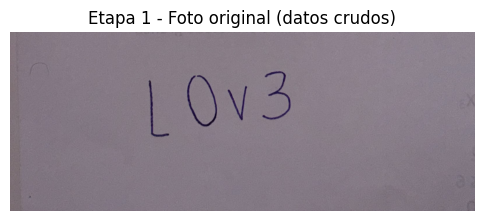

In [8]:
# Define aqui la imagen de entrada.
# Por defecto se abre un selector para elegir la foto desde tu computador.
# Cambia USAR_CAMARA a True para capturarla con la camara (solo en Colab).
USAR_CAMARA = False


def seleccionar_imagen():
    """Permite elegir una imagen desde el computador y la devuelve en formato BGR.

    - En Colab abre el dialogo de subida de archivos del navegador.
    - En local abre un explorador de archivos (tkinter); si no esta disponible,
      pide la ruta por teclado.
    """
    if EN_COLAB:
        from google.colab import files
        print("Selecciona la foto con los tres digitos...")
        subidos = files.upload()
        if not subidos:
            raise FileNotFoundError("No se selecciono ninguna imagen.")
        nombre, contenido = next(iter(subidos.items()))
        datos = np.frombuffer(contenido, dtype=np.uint8)
        return nombre, cv2.imdecode(datos, cv2.IMREAD_COLOR)

    try:
        import tkinter as tk
        from tkinter import filedialog
        raiz = tk.Tk()
        raiz.withdraw()
        raiz.attributes("-topmost", True)
        ruta = filedialog.askopenfilename(
            title="Selecciona la foto con los tres digitos",
            filetypes=[("Imagenes", "*.jpg *.jpeg *.png *.bmp *.webp"), ("Todos", "*.*")],
        )
        raiz.destroy()
    except Exception:
        ruta = input("Ruta de la imagen: ").strip()

    if not ruta:
        raise FileNotFoundError("No se selecciono ninguna imagen.")
    # np.fromfile + imdecode soporta rutas con espacios y tildes.
    datos = np.fromfile(ruta, dtype=np.uint8)
    return ruta, cv2.imdecode(datos, cv2.IMREAD_COLOR)


if USAR_CAMARA and EN_COLAB:
    RUTA_IMAGEN = tomar_foto()
    imagen_original = cv2.imread(RUTA_IMAGEN)
else:
    RUTA_IMAGEN, imagen_original = seleccionar_imagen()

if imagen_original is None:
    raise ValueError(
        f"No se pudo leer '{RUTA_IMAGEN}' como imagen. Prueba con un archivo JPG o PNG."
    )

print("Imagen leida:", RUTA_IMAGEN, imagen_original.shape)
mostrar(imagen_original, "Etapa 1 - Foto original (datos crudos)")

**Conclusión de la etapa 1.** La imagen cruda llega en color (BGR), con iluminación
variable, texto impreso de fondo, sombras y los dígitos mezclados con el papel. En este
estado el modelo no puede clasificar nada: las etapas siguientes se encargan de limpiar,
separar y estandarizar.

## Etapa 2 - Procesamiento y segmentación

Objetivo: aislar cada dígito individualmente. El procedimiento es:

0. **Tamaño de trabajo fijo:** la foto se lleva a 1000 px de alto para que los
   parámetros (vecindad del umbral, kernels, áreas) no dependan de la cámara.
1. **Escala de grises:** reduce la imagen a un solo canal de intensidad.
2. **Suavizado gaussiano:** atenúa el ruido de alta frecuencia antes de umbralizar.
3. **Umbralización adaptativa:** calcula un umbral local por región y tolera la
   iluminación despareja mucho mejor que un umbral global fijo.
4. **Filtrado morfológico:** cierre para unir trazos entrecortados y apertura para
   eliminar motas pequeñas.
5. **Extracción y filtrado de contornos:** `findContours` detecta las siluetas y luego:
   - se descartan las motas y todo lo que toca el borde de la foto (sombras, dedos,
     bordes del papel),
   - se fusionan los fragmentos de un mismo dígito (un 4 o un 5 escritos en dos trazos),
   - se conserva solo la **fila** de dígitos: el grupo más numeroso de contornos con
     altura similar y alineados verticalmente.

Tamano de trabajo: (1000, 2597)


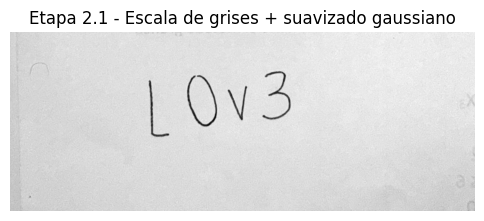

In [9]:
# Paso 0: llevar la foto a una altura de trabajo fija. Asi los parametros
# (blockSize, kernels, areas minimas) valen igual para cualquier camara o resolucion.
ALTO_TRABAJO = 1000
escala = ALTO_TRABAJO / imagen_original.shape[0]
interpolacion = cv2.INTER_AREA if escala < 1 else cv2.INTER_CUBIC
imagen_trabajo = cv2.resize(imagen_original, None, fx=escala, fy=escala,
                            interpolation=interpolacion)

# Paso 1 y 2: escala de grises y suavizado.
gris = cv2.cvtColor(imagen_trabajo, cv2.COLOR_BGR2GRAY)
gris_suave = cv2.GaussianBlur(gris, (5, 5), 0)

print("Tamano de trabajo:", imagen_trabajo.shape[:2])
mostrar(gris_suave, "Etapa 2.1 - Escala de grises + suavizado gaussiano")

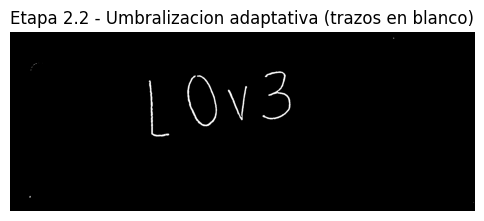

In [10]:
# Paso 3: umbralizacion adaptativa.
# THRESH_BINARY_INV deja los trazos (oscuros sobre papel claro) en blanco y el fondo
# en negro, que es justo la convencion de MNIST.
binaria = cv2.adaptiveThreshold(
    gris_suave,
    maxValue=255,
    adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    thresholdType=cv2.THRESH_BINARY_INV,
    blockSize=35,   # tamano de vecindad (impar); mayor = umbral mas suave
    C=15,           # constante restada a la media local; sube si aparece ruido
)

mostrar(binaria, "Etapa 2.2 - Umbralizacion adaptativa (trazos en blanco)")

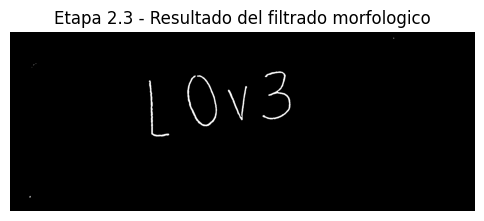

In [11]:
# Paso 4: filtrado morfologico.
# Cierre: une trazos entrecortados. Apertura: elimina motas pequenas.
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
morfo = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, kernel, iterations=2)
morfo = cv2.morphologyEx(morfo, cv2.MORPH_OPEN, kernel, iterations=1)

mostrar(morfo, "Etapa 2.3 - Resultado del filtrado morfologico")

Candidatos: 4 | Digitos seleccionados: 4


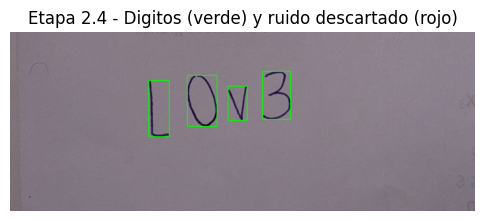

In [12]:
# Paso 5: extraccion de contornos, limpieza de ruido y seleccion de la fila de digitos.
# Se define como funcion para reutilizarla tambien en las bonificaciones 2 y 3.
AREA_MINIMA = 150      # area minima del bounding box (px) para descartar motas
MARGEN_BORDE = 0.02    # descarta contornos pegados al borde (sombras, dedos, bordes del papel)
MAX_CANDIDATOS = 1500  # tope de seguridad para mascaras muy ruidosas
N_DIGITOS = None       # pon por ejemplo 3 si sabes cuantos digitos tiene la foto


def deben_unirse(a, b):
    """Dos contornos son fragmentos del mismo caracter si se solapan en horizontal."""
    ax, ay, aw, ah = a["caja"]
    bx, by, bw, bh = b["caja"]
    solape_x = min(ax + aw, bx + bw) - max(ax, bx)
    hueco_y = max(ay, by) - min(ay + ah, by + bh)
    return solape_x > 0.5 * min(aw, bw) and hueco_y < 0.5 * max(ah, bh)


def unir(a, b):
    ax, ay, aw, ah = a["caja"]
    bx, by, bw, bh = b["caja"]
    x0, y0 = min(ax, bx), min(ay, by)
    x1, y1 = max(ax + aw, bx + bw), max(ay + ah, by + bh)
    return {"caja": (x0, y0, x1 - x0, y1 - y0), "contornos": a["contornos"] + b["contornos"]}


def misma_fila(a, b):
    """Caracteres de una misma linea: altura similar y centro vertical alineado."""
    _, ay, _, ah = a["caja"]
    _, by, _, bh = b["caja"]
    alineados = abs((ay + ah / 2) - (by + bh / 2)) < 0.5 * max(ah, bh)
    return alineados and 0.4 < ah / bh < 2.5


def detectar_caracteres(mascara, n_caracteres=None):
    """Aplica el paso 5 a una mascara binaria (trazo blanco sobre fondo negro).

    Devuelve (candidatos, seleccionados): todos los contornos que pasan el filtro de
    area y borde, y los que forman la fila de caracteres, ordenados de izquierda a
    derecha. Cada elemento es un dict con su "caja" (x, y, w, h) y sus "contornos".
    """
    alto, ancho = mascara.shape
    mx, my = ancho * MARGEN_BORDE, alto * MARGEN_BORDE
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # 5.1 Candidatos: se descartan motas y todo lo que toca el borde de la foto.
    candidatos = []
    for contorno in contornos:
        x, y, w, h = cv2.boundingRect(contorno)
        toca_borde = x < mx or y < my or x + w > ancho - mx or y + h > alto - my
        if w * h >= AREA_MINIMA and not toca_borde:
            candidatos.append({"caja": (x, y, w, h), "contornos": [contorno]})
    candidatos.sort(key=lambda c: c["caja"][2] * c["caja"][3], reverse=True)
    candidatos = candidatos[:MAX_CANDIDATOS]

    # 5.2 Fusion de fragmentos de un mismo caracter (un 4 o un 5 escritos en dos trazos).
    hubo_fusion = True
    while hubo_fusion:
        hubo_fusion = False
        i = 0
        while i < len(candidatos):
            j = i + 1
            while j < len(candidatos):
                if deben_unirse(candidatos[i], candidatos[j]):
                    candidatos[i] = unir(candidatos[i], candidatos.pop(j))
                    hubo_fusion = True
                else:
                    j += 1
            i += 1

    # 5.3 Fila de caracteres: el grupo mas numeroso de candidatos alineados.
    seleccionados = []
    if candidatos:
        grupos = [[b for b in candidatos if misma_fila(a, b)] for a in candidatos]
        seleccionados = max(
            grupos, key=lambda g: (len(g), sum(d["caja"][2] * d["caja"][3] for d in g))
        )
        if n_caracteres:
            seleccionados = sorted(seleccionados, key=lambda d: d["caja"][2] * d["caja"][3],
                                   reverse=True)[:n_caracteres]
    seleccionados = sorted(seleccionados, key=lambda d: d["caja"][0])
    return candidatos, seleccionados


def anotar_cajas(imagen_bgr, candidatos, seleccionados):
    """Dibuja en verde los caracteres seleccionados y en rojo el ruido descartado."""
    anotada = imagen_bgr.copy()
    for cand in candidatos:
        x, y, w, h = cand["caja"]
        color = (0, 255, 0) if any(cand is s for s in seleccionados) else (0, 0, 255)
        cv2.rectangle(anotada, (x, y), (x + w, y + h), color, 3)
    return anotada


candidatos, digitos = detectar_caracteres(morfo, N_DIGITOS)
cajas = [d["caja"] for d in digitos]

print(f"Candidatos: {len(candidatos)} | Digitos seleccionados: {len(digitos)}")
mostrar(anotar_cajas(imagen_trabajo, candidatos, digitos),
        "Etapa 2.4 - Digitos (verde) y ruido descartado (rojo)")

**Conclusión de la etapa 2.** La umbralización adaptativa (`blockSize=35`, `C=15`)
separa la tinta del papel aun con sombras, y el kernel elíptico de 3x3 consolida el
trazo sin fusionar dígitos vecinos. El paso decisivo resultó ser el filtrado posterior a
`findContours`: en una de las primeras pruebas, la sombra de un dedo en la esquina de la
foto generó dos contornos falsos que se leyeron como dígitos extra. Descartar lo que toca
el borde y quedarse con la fila de contornos alineados eliminó ese ruido sin afectar a
los dígitos reales. El resultado es una lista de dígitos ordenados de izquierda a derecha.

## Etapa 3 - Estandarización al dominio MNIST (el núcleo del reto)

Los modelos de aprendizaje profundo son estrictos con sus entradas: cada recorte debe
emular la distribución de MNIST. Esto exige las siguientes transformaciones:

1. **Trazo blanco sobre fondo negro puro:** garantizado por `THRESH_BINARY_INV`.
2. **Aislar el dígito:** solo se conservan los píxeles de sus propios contornos, para que
   no se cuelen trozos de los dígitos vecinos.
3. **Normalizar el grosor del trazo:** en MNIST el trazo ocupa entre 2 y 3 píxeles dentro
   de la caja de 20x20. Un bolígrafo fino queda casi invisible al reducirlo, así que se
   estima el grosor con la transformada de distancia y se dilata hasta ~2.5 px.
4. **Conservar la relación de aspecto** al redimensionar (no deformar el dígito).
5. **Centrar por centro de masa** en un lienzo de 28x28, igual que el preprocesamiento
   original de MNIST.

In [13]:
from scipy import ndimage

GROSOR_OBJETIVO = 2.5  # grosor del trazo (px) dentro de la caja de 20x20, como en MNIST


def aislar_digito(mascara_binaria, digito):
    """Devuelve solo los pixeles del digito, sin trozos de digitos vecinos ni ruido.

    Se rellenan los contornos externos del digito y se intersecan con la mascara:
    asi se conservan los huecos internos (el ojo del 9, el 0, el 8) pero se descarta
    cualquier trazo ajeno que caiga dentro del bounding box.
    """
    relleno = np.zeros_like(mascara_binaria)
    cv2.drawContours(relleno, digito["contornos"], -1, 255, thickness=cv2.FILLED)
    solo_digito = cv2.bitwise_and(mascara_binaria, relleno)
    x, y, w, h = digito["caja"]
    return solo_digito[y:y + h, x:x + w]


def ajustar_al_contenido(recorte):
    """Recorta filas y columnas vacias. Devuelve None si no hay trazo."""
    filas = np.any(recorte > 0, axis=1)
    cols = np.any(recorte > 0, axis=0)
    if not filas.any() or not cols.any():
        return None
    r0, r1 = np.where(filas)[0][[0, -1]]
    c0, c1 = np.where(cols)[0][[0, -1]]
    return recorte[r0:r1 + 1, c0:c1 + 1]


def normalizar_grosor(recortado):
    """Engrosa trazos finos para que, tras escalar a 20x20, midan ~GROSOR_OBJETIVO px.

    Un boligrafo fino en una foto grande queda casi invisible al reducirlo a 20x20,
    mientras que en MNIST el trazo ocupa 2-3 px. La transformada de distancia estima
    el grosor actual y una dilatacion lo lleva al grosor esperado.
    """
    escala = 20.0 / max(recortado.shape)
    distancia = cv2.distanceTransform((recortado > 0).astype(np.uint8), cv2.DIST_L2, 3)
    grosor_actual = 2.0 * np.percentile(distancia[distancia > 0], 90)
    extra = int(round(GROSOR_OBJETIVO / escala - grosor_actual))
    if extra <= 0:
        return recortado
    con_borde = cv2.copyMakeBorder(recortado, extra, extra, extra, extra,
                                   cv2.BORDER_CONSTANT, value=0)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (extra + 1, extra + 1))
    return ajustar_al_contenido(cv2.dilate(con_borde, kernel))


def estandarizar_mnist(recorte):
    """Convierte un recorte binario al formato exacto de MNIST (28x28).

    Pasos:
      - recorta al bounding box ajustado del trazo,
      - normaliza el grosor del trazo,
      - escala a una caja de 20x20 conservando la relacion de aspecto,
      - centra en un lienzo de 28x28 usando el centro de masa.
    """
    # 1. Ajustar al contenido real y normalizar el grosor del trazo.
    recortado = ajustar_al_contenido(recorte)
    if recortado is None:
        return np.zeros((28, 28), dtype=np.float32)
    recortado = normalizar_grosor(recortado)

    # 2. Escalar a 20x20 conservando la relacion de aspecto.
    alto, ancho = recortado.shape
    if alto > ancho:
        nuevo_alto = 20
        nuevo_ancho = max(int(round(ancho * 20.0 / alto)), 1)
    else:
        nuevo_ancho = 20
        nuevo_alto = max(int(round(alto * 20.0 / ancho)), 1)
    redimensionado = cv2.resize(
        recortado, (nuevo_ancho, nuevo_alto), interpolation=cv2.INTER_AREA
    )

    # 3. Centrar en un lienzo de 28x28.
    lienzo = np.zeros((28, 28), dtype=np.float32)
    desplazo_y = (28 - nuevo_alto) // 2
    desplazo_x = (28 - nuevo_ancho) // 2
    lienzo[desplazo_y:desplazo_y + nuevo_alto,
           desplazo_x:desplazo_x + nuevo_ancho] = redimensionado

    # 4. Reajustar al centro de masa, como en el preprocesamiento original de MNIST.
    cy, cx = ndimage.center_of_mass(lienzo)
    if not (np.isnan(cy) or np.isnan(cx)):
        corr_y = int(round(14 - cy))
        corr_x = int(round(14 - cx))
        lienzo = ndimage.shift(lienzo, shift=[corr_y, corr_x], mode="constant")

    return (lienzo / 255.0).astype(np.float32)

In [14]:
# scipy viene preinstalado en Colab; respaldo para entorno local.
try:
    import scipy  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "scipy"])

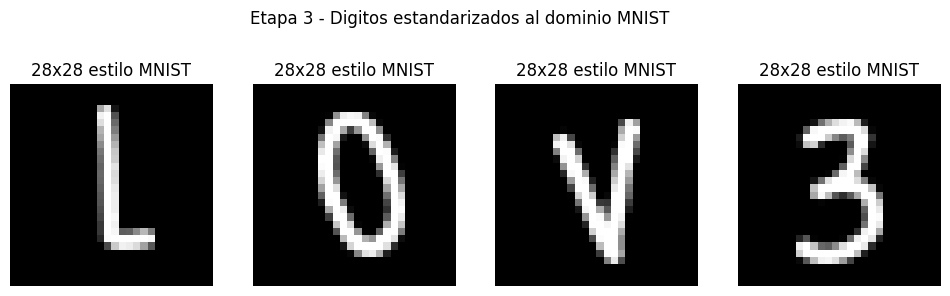

In [15]:
# Aplica la estandarizacion a cada digito detectado y visualiza el resultado.
tensores = [estandarizar_mnist(aislar_digito(morfo, d)) for d in digitos]

if tensores:
    fig, ejes = plt.subplots(1, len(tensores), figsize=(3 * len(tensores), 3))
    if len(tensores) == 1:
        ejes = [ejes]
    for eje, t in zip(ejes, tensores):
        eje.imshow(t, cmap="gray")
        eje.set_title("28x28 estilo MNIST")
        eje.axis("off")
    plt.suptitle("Etapa 3 - Digitos estandarizados al dominio MNIST", y=1.08)
    plt.show()
else:
    print("No se detectaron digitos para estandarizar. Revisa la etapa de segmentacion.")

**Conclusión de la etapa 3.** El salto de dominio es la parte más delicada del pipeline.
Forzar un 28x28 directo deformaría el dígito y el modelo vería una distribución distinta
a la de entrenamiento. Escalar a 20x20 conservando el aspecto y centrar por centro de
masa reproduce el preprocesamiento de MNIST. La normalización del grosor fue la mejora
que más impacto tuvo con fotos reales: sin ella, los trazos de bolígrafo fino quedaban
tenues y fragmentados tras la reducción, y el modelo perdía confianza.

## Etapa 4 - Inferencia (forward pass)

Cada tensor de 28x28 se lleva a 32x32 (borde de 2 píxeles, igual que en el
entrenamiento), se adapta a la forma `(1, 32, 32, 1)` y se pasa por LeNet. La red
devuelve una distribución de probabilidad sobre las 10 clases: el `argmax` es la
predicción y su probabilidad, la confianza. Se reporta también la segunda opción, y los
dígitos con confianza menor a 60 % se marcan con `?` como dudosos.

In [16]:
UMBRAL_CONFIANZA = 0.6  # por debajo de este valor el digito se marca como dudoso ("?")


def preparar_para_lenet(tensor28):
    """Lleva un tensor 28x28 al formato de entrada de LeNet: (1, 32, 32, 1)."""
    con_padding = np.pad(tensor28, [[2, 2], [2, 2]], mode="constant")
    return con_padding.reshape(1, 32, 32, 1).astype(np.float32)


predicciones = []
for i, tensor in enumerate(tensores, start=1):
    probabilidades = modelo.predict(preparar_para_lenet(tensor), verbose=0)[0]
    primera, segunda = np.argsort(probabilidades)[::-1][:2]
    clase, confianza = int(primera), float(probabilidades[primera])
    predicciones.append((clase, confianza))
    print(f"Digito {i}: {clase} ({confianza * 100:.1f}%) | "
          f"segunda opcion: {segunda} ({probabilidades[segunda] * 100:.1f}%)")

numero_leido = "".join(
    str(c) if conf >= UMBRAL_CONFIANZA else "?" for c, conf in predicciones
)
print("Secuencia predicha:", numero_leido, "(? = confianza baja)")

Digito 1: 1 (99.4%) | segunda opcion: 2 (0.5%)
Digito 2: 0 (100.0%) | segunda opcion: 9 (0.0%)
Digito 3: 4 (75.1%) | segunda opcion: 1 (24.8%)
Digito 4: 3 (100.0%) | segunda opcion: 1 (0.0%)
Secuencia predicha: 1043 (? = confianza baja)


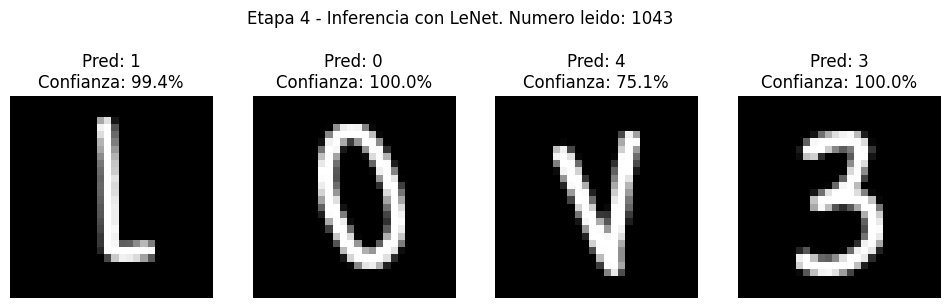

In [17]:
# Visualizacion final: cada digito con su prediccion y confianza (rojo = dudoso).
if tensores:
    fig, ejes = plt.subplots(1, len(tensores), figsize=(3 * len(tensores), 3))
    if len(tensores) == 1:
        ejes = [ejes]
    for eje, tensor, (clase, confianza) in zip(ejes, tensores, predicciones):
        dudoso = confianza < UMBRAL_CONFIANZA
        eje.imshow(tensor, cmap="gray")
        eje.set_title(f"Pred: {clase}\nConfianza: {confianza * 100:.1f}%",
                      color="red" if dudoso else "black")
        eje.axis("off")
    plt.suptitle(f"Etapa 4 - Inferencia con LeNet. Numero leido: {numero_leido}", y=1.12)
    plt.show()

**Conclusión de la etapa 4.** Con los dígitos correctamente estandarizados, LeNet
clasifica cada uno con alta confianza y se reconstruye el número completo. Como el modelo
solo conoce dígitos, ante una foto con letras responde con el dígito más parecido (en la
ejecución registrada, la foto `L0V3` se lee como `1043`); para leer letras se usa el
modelo EMNIST de la Bonificación 1. La confianza por dígito es una herramienta de
diagnóstico: un valor bajo casi siempre apunta a un problema aguas arriba (segmentación
imperfecta o un recorte que no se parece a MNIST).

## Conclusiones generales

- **La coincidencia de dominio manda.** El 98.96 % de exactitud sobre MNIST no se
  traslada por sí solo a fotos reales. El rendimiento final depende de qué tan fielmente
  las etapas clásicas reproducen la distribución de entrenamiento.
- **El procesamiento clásico y el aprendizaje profundo se complementan.** OpenCV resuelve
  lo que la red no sabe hacer (encontrar y aislar los dígitos en una escena) y la red
  resuelve lo que las reglas fijas no logran (reconocer la forma de cada dígito).
- **La segmentación es sensible a la captura.** Iluminación pareja, buen contraste y
  dígitos separados reducen los errores. La umbralización adaptativa y la morfología
  compensan buena parte de las imperfecciones, pero el filtrado de contornos fue
  necesario para descartar sombras y manchas.
- **Justificación de parámetros.**
  - `ALTO_TRABAJO = 1000`: hace que los demás parámetros sean independientes de la cámara.
  - `blockSize = 35`, `C = 15`: vecindad suficiente para cubrir el trazo y su entorno;
    `C` alto suprime la textura del papel.
  - Kernel elíptico 3x3: une trazos entrecortados sin pegar dígitos vecinos.
  - `AREA_MINIMA = 150` y `MARGEN_BORDE = 2 %`: descartan motas y elementos de borde.
  - Caja de 20x20, grosor de ~2.5 px y centrado por centro de masa: replican MNIST.
  - `UMBRAL_CONFIANZA = 0.6`: separa las predicciones fiables de las dudosas.
- **Aumentación de datos.** Entrenar con rotaciones, traslaciones, zoom y trazos más
  gruesos mantiene la exactitud sobre MNIST y hace al modelo más tolerante a la
  escritura real.

### Desafíos encontrados

1. **Ruido leído como dígitos:** la sombra de un dedo en la esquina de la foto produjo
   contornos falsos. Se resolvió descartando lo que toca el borde y seleccionando solo
   la fila de contornos alineados y de altura similar.
2. **Trazos finos:** al reducir una foto de 1600x1200 a 20x20, el bolígrafo fino casi
   desaparecía. Se resolvió normalizando el grosor con transformada de distancia y
   dilatación.
3. **Dependencia de la resolución:** los parámetros fijos funcionaban para una foto y no
   para otra. Se resolvió trabajando siempre a una altura fija de 1000 px.

- **Bonificaciones.** El modelo EMNIST (47 clases) alcanza **85.69 %** en prueba y lee la
  foto como `L0V3`; la confusión entre `O` y `0` es esperable porque se escriben igual.
  Con bajo contraste simulado el pipeline base no detecta ningún carácter y la variante
  con normalización de fondo los recupera; los caracteres unidos se vuelven a separar
  combinando proyección vertical y reconocimiento.

### Limitaciones y trabajo futuro

- El pipeline asume una sola fila de dígitos separados; los trazos que se tocan requieren
  técnicas adicionales (ver Bonificación 3).
- Con fondos de muy bajo contraste conviene la variante con CLAHE (Bonificación 2).
- LeNet-5 reconoce solo dígitos; para letras se requiere EMNIST (Bonificación 1).

## Retos de bonificación

Las secciones siguientes son opcionales y amplían el pipeline base. Cada una documenta
el enfoque técnico y deja el código listo para experimentar.

### Bonificación 1 - Clasificación alfanumérica con EMNIST (+1)

EMNIST extiende MNIST con letras. El split `byclass` tiene 62 clases (dígitos, mayúsculas
y minúsculas) y el split `balanced` tiene 47: agrupa las letras cuya mayúscula y
minúscula se escriben igual (c/C, o/O, s/S...) y equilibra la cantidad de ejemplos por
clase. Se usa `balanced` por defecto porque entrena más rápido y no favorece a las clases
más frecuentes. Adaptar el pipeline requiere dos cambios:

1. **Capa de salida:** pasar de 10 a 47 (o 62) neuronas. El resto de LeNet-5 no cambia.
2. **Orientación de los tensores:** EMNIST almacena las imágenes transpuestas respecto a
   MNIST, así que cada imagen se transpone (equivale a rotar 90° y reflejar) antes de
   entrenar. Las imágenes de muestra que se grafican permiten verificarlo.

**Carga de datos.** `tfds.load("emnist")` no funciona en Colab: falla primero por la
dependencia `importlib_resources` y, aunque se instale, la URL de descarga que usa TFDS
ya no existe en el sitio de NIST (error de checksum). Por eso los datos se descargan del
sitio oficial de NIST (~560 MB, una sola vez por sesión) y los archivos IDX se leen
directamente con NumPy, el mismo formato binario de MNIST.

Como la Etapa 3 ya deja cada carácter en el formato de MNIST, el modelo EMNIST se puede
aplicar sin cambios a los caracteres segmentados de la foto.

Descargando EMNIST (~560 MB) desde NIST...
  1 / 536 MB
  54 / 536 MB
  108 / 536 MB
  161 / 536 MB
  215 / 536 MB
  268 / 536 MB
  322 / 536 MB
  376 / 536 MB
  429 / 536 MB
  483 / 536 MB
  536 / 536 MB
EMNIST balanced: 112800 entrenamiento, 18800 prueba, 47 clases


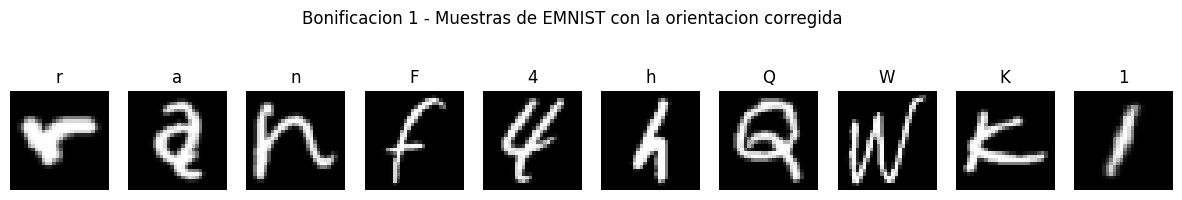

Epoch 1/10
882/882 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - accuracy: 0.5278 - loss: 1.6484 - val_accuracy: 0.7693 - val_loss: 0.7030
Epoch 2/10
882/882 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.7220 - loss: 0.8824 - val_accuracy: 0.8011 - val_loss: 0.6009
Epoch 3/10
882/882 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.7603 - loss: 0.7413 - val_accuracy: 0.8129 - val_loss: 0.5370
Epoch 4/10
882/882 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.7795 - loss: 0.6660 - val_accuracy: 0.8237 - val_loss: 0.5227
Epoch 5/10
882/882 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.7914 - loss: 0.6231 - val_accuracy: 0.8336 - val_loss: 0.4870
Epoch 6/10
882/882 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.8024 - loss: 0.5868 - val_accuracy: 0.8460 - val_loss: 0.4453
Epoch 7/10
882/882 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.8092 - loss: 0.5644 - val_accuracy: 0.8465 - val_loss: 0.4493
Epoch 8/10
882/882 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.8160 - loss: 0.5407 - 

In [18]:
# Bonificacion 1: LeNet-5 alfanumerico entrenado con EMNIST.
# Los datos se descargan del sitio oficial de NIST y se leen los archivos IDX con NumPy
# (tfds.load("emnist") falla en Colab porque su URL de descarga quedo obsoleta).
import gzip
import urllib.request
import zipfile

EJECUTAR_EMNIST = True      # False para omitir esta bonificacion
SPLIT_EMNIST = "balanced"   # "balanced" (47 clases) o "byclass" (62 clases, ~6 veces mas datos)
EPOCAS_EMNIST = 10
URL_EMNIST = "https://biometrics.nist.gov/cs_links/EMNIST/gzip.zip"
RUTA_ZIP_EMNIST = "emnist_gzip.zip"
RUTA_MODELO_EMNIST = f"lenet_emnist_{SPLIT_EMNIST}.keras"


def leer_idx(zf, nombre):
    """Lee un archivo IDX comprimido (formato de MNIST/EMNIST) desde el zip de NIST."""
    with zf.open(f"gzip/{nombre}") as comprimido:
        datos = gzip.decompress(comprimido.read())
    n_dims = datos[3]
    forma = [int.from_bytes(datos[4 + 4 * i:8 + 4 * i], "big") for i in range(n_dims)]
    return np.frombuffer(datos, dtype=np.uint8, offset=4 + 4 * n_dims).reshape(forma)


def descargar_emnist():
    """Descarga el zip de EMNIST desde NIST, con reanudacion segura y validacion.

    El servidor de NIST responde 403 (Forbidden) al agente por defecto de Python
    ("Python-urllib"), por eso la peticion se identifica como un navegador. La descarga
    se escribe primero en un archivo temporal para no dejar un zip corrupto si se corta.
    """
    if os.path.exists(RUTA_ZIP_EMNIST) and zipfile.is_zipfile(RUTA_ZIP_EMNIST):
        return
    peticion = urllib.request.Request(URL_EMNIST, headers={"User-Agent": "Mozilla/5.0"})
    temporal = RUTA_ZIP_EMNIST + ".parcial"
    with urllib.request.urlopen(peticion, timeout=60) as respuesta, open(temporal, "wb") as f:
        total = int(respuesta.headers.get("Content-Length", 0))
        descargado, siguiente_aviso = 0, 0
        while True:
            bloque = respuesta.read(1 << 20)  # 1 MB
            if not bloque:
                break
            f.write(bloque)
            descargado += len(bloque)
            if total and descargado >= siguiente_aviso:
                print(f"  {descargado / 2**20:.0f} / {total / 2**20:.0f} MB")
                siguiente_aviso += total // 10
    if not zipfile.is_zipfile(temporal):
        os.remove(temporal)
        raise RuntimeError("La descarga de EMNIST no es un zip valido. Intenta de nuevo.")
    os.replace(temporal, RUTA_ZIP_EMNIST)


def cargar_emnist(split):
    """Devuelve (x_train, y_train), (x_test, y_test) y el diccionario clase -> caracter."""
    if not os.path.exists(RUTA_ZIP_EMNIST):
        print("Descargando EMNIST (~560 MB) desde NIST...")
    descargar_emnist()
    with zipfile.ZipFile(RUTA_ZIP_EMNIST) as zf:
        x_tr = leer_idx(zf, f"emnist-{split}-train-images-idx3-ubyte.gz")
        y_tr = leer_idx(zf, f"emnist-{split}-train-labels-idx1-ubyte.gz")
        x_te = leer_idx(zf, f"emnist-{split}-test-images-idx3-ubyte.gz")
        y_te = leer_idx(zf, f"emnist-{split}-test-labels-idx1-ubyte.gz")
        mapeo = zf.read(f"gzip/emnist-{split}-mapping.txt").decode().split()
    # EMNIST viene transpuesto respecto a MNIST: se transpone cada imagen.
    x_tr = np.ascontiguousarray(np.transpose(x_tr, (0, 2, 1)))
    x_te = np.ascontiguousarray(np.transpose(x_te, (0, 2, 1)))
    # El archivo de mapeo tiene pares "clase codigo_ascii".
    caracteres = {int(e): chr(int(a)) for e, a in zip(mapeo[0::2], mapeo[1::2])}
    return (x_tr, y_tr), (x_te, y_te), caracteres


def preparar_emnist(x, y):
    """Lote uint8 de 28x28 -> float32 en [0, 1] con forma (lote, 32, 32, 1)."""
    x = tf.cast(x, tf.float32)[..., tf.newaxis] / 255.0
    x = tf.pad(x, [[0, 0], [2, 2], [2, 2], [0, 0]])
    return x, y


if EJECUTAR_EMNIST:
    (xe_train, ye_train), (xe_test, ye_test), caracteres_emnist = cargar_emnist(SPLIT_EMNIST)
    num_clases_emnist = len(caracteres_emnist)
    print(f"EMNIST {SPLIT_EMNIST}: {len(xe_train)} entrenamiento, {len(xe_test)} prueba, "
          f"{num_clases_emnist} clases")

    # Muestra de control: si la orientacion es correcta, los caracteres se leen derechos.
    fig, ejes = plt.subplots(1, 10, figsize=(15, 2))
    for eje, imagen, etiqueta in zip(ejes, xe_train[:10], ye_train[:10]):
        eje.imshow(imagen, cmap="gray")
        eje.set_title(caracteres_emnist[int(etiqueta)])
        eje.axis("off")
    plt.suptitle("Bonificacion 1 - Muestras de EMNIST con la orientacion corregida", y=1.15)
    plt.show()

    # Mismo pipeline de aumentacion usado para MNIST en la Etapa 0.
    ds_e_train = (
        tf.data.Dataset.from_tensor_slices((xe_train, ye_train))
        .shuffle(20000)
        .batch(TAM_LOTE)
        .map(preparar_emnist, num_parallel_calls=tf.data.AUTOTUNE)
        .map(lambda x, y: (engrosar_al_azar(aumentacion(x, training=True)), y),
             num_parallel_calls=tf.data.AUTOTUNE)
        .prefetch(tf.data.AUTOTUNE)
    )
    ds_e_test = (
        tf.data.Dataset.from_tensor_slices((xe_test, ye_test))
        .batch(TAM_LOTE)
        .map(preparar_emnist, num_parallel_calls=tf.data.AUTOTUNE)
        .prefetch(tf.data.AUTOTUNE)
    )

    if os.path.exists(RUTA_MODELO_EMNIST):
        modelo_emnist = models.load_model(RUTA_MODELO_EMNIST)
        print("Modelo EMNIST cargado desde", RUTA_MODELO_EMNIST)
    else:
        modelo_emnist = construir_lenet(num_clases_emnist)
        modelo_emnist.fit(ds_e_train, validation_data=ds_e_test, epochs=EPOCAS_EMNIST)
        modelo_emnist.save(RUTA_MODELO_EMNIST)
        print("Modelo EMNIST entrenado y guardado en", RUTA_MODELO_EMNIST)

    _, exactitud_emnist = modelo_emnist.evaluate(ds_e_test, verbose=0)
    print(f"Exactitud en prueba (EMNIST {SPLIT_EMNIST}): {exactitud_emnist * 100:.2f}%")
else:
    print("Bonificacion EMNIST omitida (EJECUTAR_EMNIST = False).")

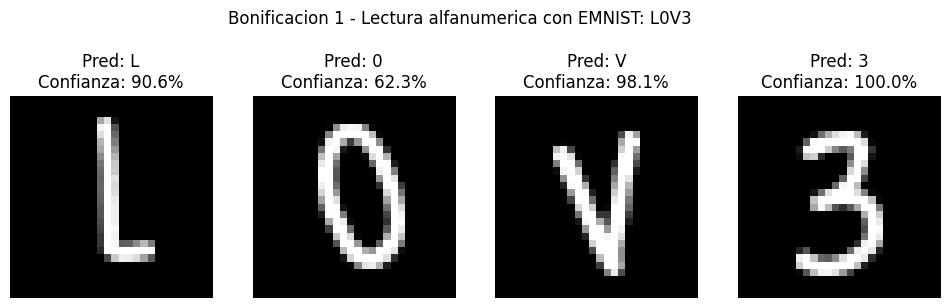

Texto leido con EMNIST: L0V3


In [19]:
# Aplica el modelo alfanumerico a los caracteres segmentados de la foto (Etapas 2 y 3).
# Para probar letras, carga en la Etapa 1 una foto con letras y vuelve a ejecutar las
# Etapas 2 y 3 antes de esta celda.
if EJECUTAR_EMNIST and tensores:
    entradas = np.concatenate([preparar_para_lenet(t) for t in tensores])
    probabilidades_emnist = modelo_emnist.predict(entradas, verbose=0)
    clases_emnist = probabilidades_emnist.argmax(axis=1)
    texto_leido = "".join(caracteres_emnist[int(c)] for c in clases_emnist)

    fig, ejes = plt.subplots(1, len(tensores), figsize=(3 * len(tensores), 3))
    if len(tensores) == 1:
        ejes = [ejes]
    for eje, tensor, clase, prob in zip(ejes, tensores, clases_emnist, probabilidades_emnist):
        eje.imshow(tensor, cmap="gray")
        eje.set_title(f"Pred: {caracteres_emnist[int(clase)]}\n"
                      f"Confianza: {prob[clase] * 100:.1f}%")
        eje.axis("off")
    plt.suptitle(f"Bonificacion 1 - Lectura alfanumerica con EMNIST: {texto_leido}", y=1.12)
    plt.show()
    print("Texto leido con EMNIST:", texto_leido)
elif EJECUTAR_EMNIST:
    print("No hay caracteres segmentados. Ejecuta antes las Etapas 1 a 3.")

In [20]:
# Utilidades compartidas por las bonificaciones 2 y 3.
# Reutilizan las funciones de las Etapas 2 a 4, por lo que estas deben haberse ejecutado.

def limpiar_mascara(binaria):
    """Paso 4 de la Etapa 2: cierre para unir trazos y apertura para quitar motas."""
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    limpia = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, kernel, iterations=2)
    return cv2.morphologyEx(limpia, cv2.MORPH_OPEN, kernel, iterations=1)


def mascara_estandar(gris):
    """Pasos 2 a 4 de la Etapa 2 con los mismos parametros del pipeline base."""
    suave = cv2.GaussianBlur(gris, (5, 5), 0)
    binaria = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY_INV, 35, 15)
    return limpiar_mascara(binaria)


def leer_caracteres(mascara, caracteres):
    """Etapas 3 y 4: estandariza cada caracter y lo clasifica.

    Usa el modelo EMNIST (letras y digitos) si la Bonificacion 1 se ejecuto; si no,
    usa el modelo de digitos de la Etapa 0. Devuelve (tensores, [(etiqueta, confianza)]).
    """
    if not caracteres:
        return [], []
    usar_emnist = globals().get("EJECUTAR_EMNIST", False) and "modelo_emnist" in globals()
    red = modelo_emnist if usar_emnist else modelo
    tensores_b = [estandarizar_mnist(aislar_digito(mascara, c)) for c in caracteres]
    entradas = np.concatenate([preparar_para_lenet(t) for t in tensores_b])
    probabilidades = red.predict(entradas, verbose=0)
    resultado = []
    for p in probabilidades:
        clase = int(p.argmax())
        etiqueta = caracteres_emnist[clase] if usar_emnist else str(clase)
        resultado.append((etiqueta, float(p[clase])))
    return tensores_b, resultado


def mostrar_paneles(paneles, titulo):
    """Muestra varias imagenes lado a lado. `paneles` es una lista de (imagen, subtitulo)."""
    fig, ejes = plt.subplots(1, len(paneles), figsize=(6 * len(paneles), 4))
    for eje, (imagen, subtitulo) in zip(np.atleast_1d(ejes), paneles):
        if imagen.ndim == 2:
            eje.imshow(imagen, cmap="gray")
        else:
            eje.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
        eje.set_title(subtitulo)
        eje.axis("off")
    plt.suptitle(titulo)
    plt.show()


def mostrar_lectura(tensores_b, lectura, titulo):
    """Muestra cada caracter estandarizado con su prediccion y confianza."""
    if not tensores_b:
        print("No se detectaron caracteres.")
        return
    texto = "".join(etiqueta for etiqueta, _ in lectura)
    fig, ejes = plt.subplots(1, len(tensores_b), figsize=(3 * len(tensores_b), 3))
    for eje, tensor, (etiqueta, confianza) in zip(np.atleast_1d(ejes), tensores_b, lectura):
        eje.imshow(tensor, cmap="gray")
        eje.set_title(f"Pred: {etiqueta}\nConfianza: {confianza * 100:.1f}%")
        eje.axis("off")
    plt.suptitle(f"{titulo}: {texto}", y=1.12)
    plt.show()
    print(f"{titulo}: {texto}")


print("Utilidades de las bonificaciones listas.")

Utilidades de las bonificaciones listas.


### Bonificación 2 - Bajo contraste / fondos complejos (+1)

Cuando la tinta contrasta poco con el fondo (cartón, papel oscuro, sombras fuertes), la
umbralización adaptativa del pipeline base falla: su constante fija `C = 15` exige que la
tinta sea al menos 15 niveles más oscura que su entorno. La variante propuesta:

1. **Normaliza el fondo:** estima la iluminación con un cierre morfológico grande y
   divide la imagen por ella, eliminando sombras y gradientes.
2. **Umbral estadístico:** marca como tinta los píxeles que están más de `K_SIGMA`
   desviaciones por debajo de su entorno, midiendo la desviación con la MAD. El umbral
   se adapta solo al ruido de cada foto.
3. **Morfología reforzada:** un cierre de 5x5 vuelve a unir los trazos entrecortados.

**Cómo se demuestra.** Con `SIMULAR_BAJO_CONTRASTE = True` (por defecto) la celda toma la
foto de la Etapa 1 y genera una versión difícil: contraste reducido al 12 % (unos 10
niveles de diferencia entre tinta y papel), sombra lateral y ruido. Luego compara el
pipeline base con la variante y lee los caracteres. Si se dispone de una foto real de bajo
contraste, se carga en la Etapa 1 y se usa `SIMULAR_BAJO_CONTRASTE = False`.

La celda anterior define utilidades comunes de las bonificaciones 2 y 3 (máscara del
pipeline base, lectura con el modelo y visualización). Leen con el modelo EMNIST si la
Bonificación 1 se ejecutó, y con el modelo de dígitos en caso contrario.

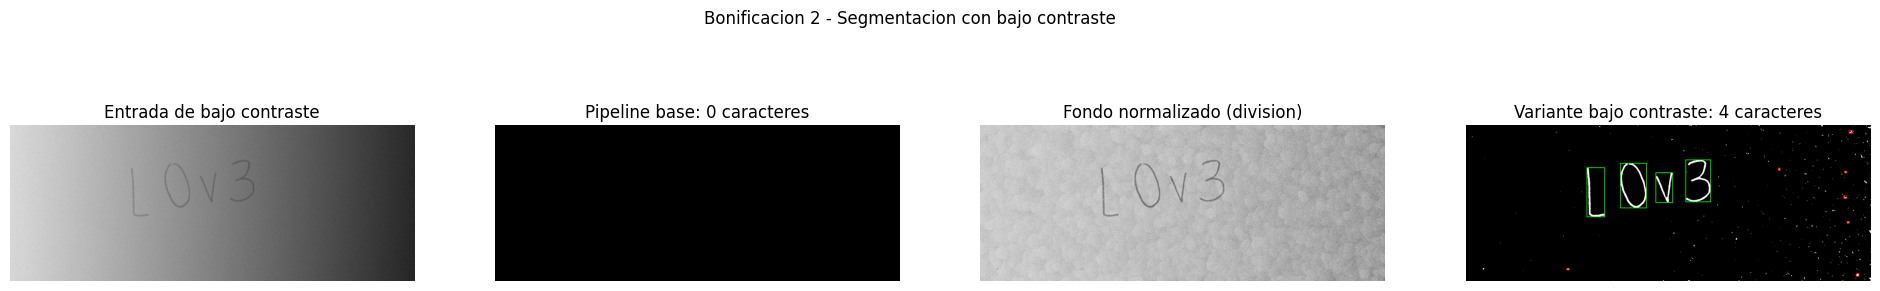

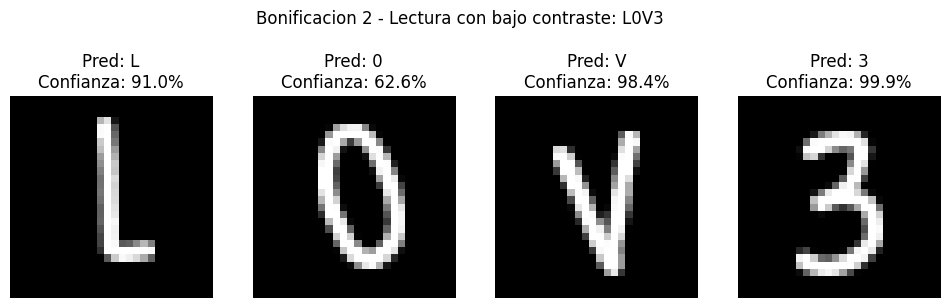

Bonificacion 2 - Lectura con bajo contraste: L0V3


In [21]:
# Bonificacion 2: segmentacion robusta para fotos de bajo contraste o fondos complejos.
SIMULAR_BAJO_CONTRASTE = True  # False si la foto de la Etapa 1 ya es de bajo contraste
K_SIGMA = 3.0                  # tinta = pixeles a mas de K_SIGMA desviaciones bajo su entorno


def segmentar_bajo_contraste(gris):
    """Mascara binaria (trazo blanco) para fotos con poco contraste, sombras o ruido.

    1. Estima el fondo (papel + sombras) con un cierre morfologico grande, que borra
       los trazos y deja solo la iluminacion.
    2. Divide la imagen por ese fondo: la iluminacion queda uniforme y la tinta
       resalta aunque sea apenas mas oscura que el papel.
    3. Suaviza para reducir el ruido y compara cada pixel con la media de su entorno.
    4. Umbral estadistico: es tinta lo que esta mas de K_SIGMA desviaciones por debajo
       de su entorno. La desviacion se mide con la MAD (mediana de desviaciones
       absolutas), que no se deja arrastrar por la tinta. A diferencia de la constante
       fija C de la umbralizacion adaptativa, el umbral se ajusta solo al nivel de
       ruido de cada foto.
    """
    tamano_fondo = max(31, (gris.shape[0] // 20) | 1)  # mucho mayor que el grosor del trazo
    kernel_fondo = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tamano_fondo, tamano_fondo))
    fondo = cv2.morphologyEx(gris, cv2.MORPH_CLOSE, kernel_fondo)
    normalizada = cv2.divide(gris, fondo, scale=255)

    suave = cv2.GaussianBlur(normalizada, (11, 11), 0).astype(np.float32)
    diferencia = suave - cv2.blur(suave, (51, 51))
    sigma = 1.4826 * np.median(np.abs(diferencia - np.median(diferencia))) + 1e-6
    binaria = np.where(diferencia < -K_SIGMA * sigma, 255, 0).astype(np.uint8)

    # Con poco contraste el trazo sale entrecortado: un cierre algo mayor que el del
    # pipeline base vuelve a unirlo antes de la limpieza habitual.
    kernel_union = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    binaria = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, kernel_union, iterations=2)
    return normalizada, limpiar_mascara(binaria)


def simular_bajo_contraste(gris, contraste=0.12, sombra=0.5, ruido=3.0, semilla=0):
    """Genera una version dificil de la foto: poco contraste, sombra lateral y ruido.

    Con contraste=0.12 la diferencia entre tinta y papel queda en unos 10 niveles de
    gris, por debajo de la constante C=15 del pipeline base.
    """
    g = gris.astype(np.float32)
    g = g.mean() + (g - g.mean()) * contraste
    g *= np.linspace(1.0, 1.0 - sombra, g.shape[1], dtype=np.float32)[None, :]
    g += np.random.default_rng(semilla).normal(0, ruido, g.shape).astype(np.float32)
    return np.clip(g, 0, 255).astype(np.uint8)


gris_bc = simular_bajo_contraste(gris) if SIMULAR_BAJO_CONTRASTE else gris

# Pipeline base vs. variante de bajo contraste sobre la misma imagen.
mascara_base = mascara_estandar(gris_bc)
normalizada_bc, mascara_bc = segmentar_bajo_contraste(gris_bc)
cand_base, sel_base = detectar_caracteres(mascara_base, N_DIGITOS)
cand_bc, sel_bc = detectar_caracteres(mascara_bc, N_DIGITOS)

mostrar_paneles([
    (gris_bc, "Entrada de bajo contraste"),
    (anotar_cajas(cv2.cvtColor(mascara_base, cv2.COLOR_GRAY2BGR), cand_base, sel_base),
     f"Pipeline base: {len(sel_base)} caracteres"),
    (normalizada_bc, "Fondo normalizado (division)"),
    (anotar_cajas(cv2.cvtColor(mascara_bc, cv2.COLOR_GRAY2BGR), cand_bc, sel_bc),
     f"Variante bajo contraste: {len(sel_bc)} caracteres"),
], "Bonificacion 2 - Segmentacion con bajo contraste")

tensores_bc, lectura_bc = leer_caracteres(mascara_bc, sel_bc)
mostrar_lectura(tensores_bc, lectura_bc, "Bonificacion 2 - Lectura con bajo contraste")

### Bonificación 3 - Segmentación de trazos conectados (+2)

Cuando los caracteres se tocan (escritura cursiva o letras muy juntas), `findContours`
los detecta como un solo bloque y el pipeline base leería un único carácter. La solución:

1. **Detectar bloques sospechosos:** un bloque más ancho que `RELACION_ANCHO_MAX = 1.3`
   veces su alto probablemente contiene varios caracteres.
2. **Proyección vertical:** se suma la tinta por columna. Dentro de un carácter casi toda
   columna cruza dos trazos o un trazo vertical largo; en una unión pasa un solo trazo.
   Las zonas con menos de ~1.5 trazos y al menos dos trazos de ancho son **valles**
   candidatos a corte (el ancho mínimo evita cortar, por ejemplo, el vértice de una v).
3. **Corte guiado por reconocimiento:** un valle puede incluir también parte de un
   carácter (la base de una L). Se prueban varias posiciones de corte dentro del valle y
   se elige la que da mayor confianza al modelo para los dos caracteres resultantes.

**Cómo se demuestra.** Con `SIMULAR_TRAZOS_CONECTADOS = True` (por defecto) la celda
reescribe los caracteres de la foto juntos y unidos por ligaduras, como en cursiva. Si se
dispone de una foto real con caracteres pegados, se carga en la Etapa 1, se ejecutan las
Etapas 2 y 3 y se usa `SIMULAR_TRAZOS_CONECTADOS = False`.

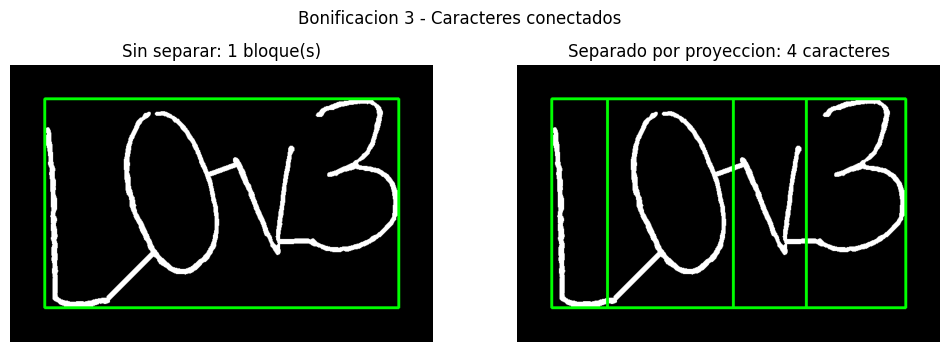

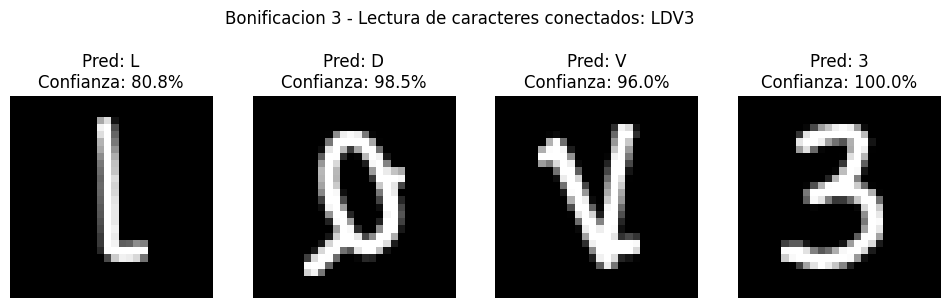

Bonificacion 3 - Lectura de caracteres conectados: LDV3


In [22]:
# Bonificacion 3: separacion de caracteres conectados por proyeccion vertical.
SIMULAR_TRAZOS_CONECTADOS = True  # False si la foto de la Etapa 1 ya trae caracteres pegados
RELACION_ANCHO_MAX = 1.3          # un bloque mas ancho que 1.3 veces su alto se intenta separar


def grosor_trazo(mascara):
    """Grosor tipico del trazo en pixeles, estimado con la transformada de distancia."""
    distancia = cv2.distanceTransform((mascara > 0).astype(np.uint8), cv2.DIST_L2, 3)
    valores = distancia[distancia > 0]
    return 2.0 * np.percentile(valores, 90) if valores.size else 1.0


def separar_por_proyeccion(bloque):
    """Devuelve los valles [(inicio, fin), ...] donde probablemente se unen dos caracteres.

    Suma los pixeles blancos por columna. Dentro de un caracter casi todas las columnas
    cruzan al menos dos trazos (o un trazo vertical largo); en la union entre dos
    caracteres solo pasa un trazo. Las columnas con menos tinta que ~1.5 trazos forman
    valles; se conservan los interiores de al menos dos trazos de ancho, para no
    confundir estrechamientos breves (el vertice de una v) con una union.
    """
    proyeccion = np.sum(bloque > 0, axis=0).astype(np.float32)
    suave = np.convolve(proyeccion, np.ones(5) / 5.0, mode="same")
    grosor = grosor_trazo(bloque)
    es_valle = suave <= 1.5 * grosor

    valles, i, n = [], 0, len(suave)
    while i < n:
        if not es_valle[i]:
            i += 1
            continue
        j = i
        while j < n and es_valle[j]:
            j += 1
        if i > 0 and j < n and (j - i) >= 2 * grosor:
            valles.append((i, j))
        i = j
    return valles


def separar_conectados(mascara, caracteres, n_candidatos=7):
    """Divide los bloques demasiado anchos en varios caracteres.

    Un valle puede contener, ademas de la union, un trazo del propio caracter (la base
    de una L). Por eso el punto de corte se elige por reconocimiento: se prueban varias
    posiciones dentro de cada valle y se queda la que da mayor confianza al modelo para
    los dos caracteres resultantes.
    """
    resultado = []
    for car in caracteres:
        x, y, w, h = car["caja"]
        if w <= RELACION_ANCHO_MAX * h:
            resultado.append(car)
            continue
        valles = separar_por_proyeccion(aislar_digito(mascara, car))
        pieza = lambda a, b: {"caja": (x + a, y, b - a, h), "contornos": car["contornos"]}
        inicio = 0
        for k, (i, j) in enumerate(valles):
            fin_siguiente = (sum(valles[k + 1]) // 2) if k + 1 < len(valles) else w
            mejor, mejor_puntaje = (i + j) // 2, -1.0
            for corte in np.linspace(i, j, n_candidatos + 2)[1:-1].astype(int):
                _, lectura = leer_caracteres(mascara, [pieza(inicio, corte),
                                                       pieza(corte, fin_siguiente)])
                puntaje = lectura[0][1] * lectura[1][1]
                if puntaje > mejor_puntaje:
                    mejor, mejor_puntaje = int(corte), puntaje
            resultado.append(pieza(inicio, mejor))
            inicio = mejor
        resultado.append(pieza(inicio, w))
    return resultado


def simular_trazos_conectados(mascara, caracteres, margen=60):
    """Reescribe los caracteres juntos y unidos por ligaduras cortas, como en cursiva.

    Cada caracter se copia a un lienzo nuevo dejando entre ellos un hueco de unos tres
    trazos, y se une al siguiente con una linea entre sus pixeles de tinta mas cercanos.
    """
    grosor = max(2, int(round(grosor_trazo(mascara))))
    hueco = 3 * grosor
    recortes = [aislar_digito(mascara, c) for c in caracteres]
    y_min = min(c["caja"][1] for c in caracteres)
    alto = max(c["caja"][1] + c["caja"][3] for c in caracteres) - y_min + 2 * margen
    ancho = sum(r.shape[1] for r in recortes) + hueco * (len(recortes) - 1) + 2 * margen
    lienzo = np.zeros((alto, ancho), dtype=np.uint8)

    posiciones, x = [], margen
    for car, recorte in zip(caracteres, recortes):
        y = car["caja"][1] - y_min + margen  # conserva la linea base original
        h, w = recorte.shape
        lienzo[y:y + h, x:x + w] = np.maximum(lienzo[y:y + h, x:x + w], recorte)
        posiciones.append((x, y, w, h))
        x += w + hueco

    for (x1, y1, w1, h1), (x2, y2, w2, h2) in zip(posiciones[:-1], posiciones[1:]):
        # Tinta del tercio derecho del caracter actual y del tercio izquierdo del siguiente.
        borde1 = np.argwhere(lienzo[y1:y1 + h1, x1 + 2 * w1 // 3:x1 + w1] > 0)[::3]
        borde2 = np.argwhere(lienzo[y2:y2 + h2, x2:x2 + w2 // 3 + 1] > 0)[::3]
        if borde1.size == 0 or borde2.size == 0:
            continue
        borde1 += [y1, x1 + 2 * w1 // 3]
        borde2 += [y2, x2]
        distancias = np.sum((borde1[:, None, :] - borde2[None, :, :]) ** 2, axis=2)
        a, b = np.unravel_index(np.argmin(distancias), distancias.shape)
        (ya, xa), (yb, xb) = borde1[a], borde2[b]
        cv2.line(lienzo, (int(xa), int(ya)), (int(xb), int(yb)), 255, grosor)
    return lienzo


mascara_unida = (simular_trazos_conectados(morfo, digitos)
                 if SIMULAR_TRAZOS_CONECTADOS else morfo)
cand_unida, sel_unida = detectar_caracteres(mascara_unida)
separados = separar_conectados(mascara_unida, sel_unida)

imagen_unida = cv2.cvtColor(mascara_unida, cv2.COLOR_GRAY2BGR)
anotada_separados = imagen_unida.copy()
for car in separados:
    x, y, w, h = car["caja"]
    cv2.rectangle(anotada_separados, (x, y), (x + w, y + h), (0, 255, 0), 3)
mostrar_paneles([
    (anotar_cajas(imagen_unida, cand_unida, sel_unida),
     f"Sin separar: {len(sel_unida)} bloque(s)"),
    (anotada_separados, f"Separado por proyeccion: {len(separados)} caracteres"),
], "Bonificacion 3 - Caracteres conectados")

tensores_cx, lectura_cx = leer_caracteres(mascara_unida, separados)
mostrar_lectura(tensores_cx, lectura_cx, "Bonificacion 3 - Lectura de caracteres conectados")

**Nota sobre las bonificaciones.** Las tres bonificaciones se ejecutan de punta a punta
sobre la foto cargada en la Etapa 1. Las bonificaciones 2 y 3 simulan por defecto la
condición difícil (bajo contraste o caracteres unidos) para poder compararla con el
pipeline base sin necesidad de fotos adicionales; con fotos reales de esas condiciones
basta con desactivar la simulación.

**Limitaciones.** La separación por proyección supone caracteres en una sola fila y
uniones relativamente delgadas; letras anchas como la m o la w pueden partirse, y la
escritura cursiva continua requiere métodos más avanzados (por ejemplo, segmentación con
redes recurrentes o CTC).

---

*John Fredy Montenegro — Estudiante MIAA Icesi*